In [1]:
import numpy as np
from sklearn.model_selection import KFold, TimeSeriesSplit

# Simulasi 10 titik waktu berurutan
X_dummy = np.array([[i] for i in range(10)])

# [SALAH] K-Fold Tradisional (Mengacak urutan / memutus kronologi)
kf = KFold(n_splits=3, shuffle=True, random_state=42)
print("Standard K-Fold (Contoh Kebocoran Data):")
for train_index, test_index in kf.split(X_dummy):
    print(f"Train: {train_index} | Test: {test_index}")

print("-" * 50)

# [BENAR] Time Series Split (Menjaga kronologi)
tscv = TimeSeriesSplit(n_splits=3)
print("Time Series Split (Aman dari Kebocoran):")
for train_index, test_index in tscv.split(X_dummy):
    print(f"Train: {train_index} | Test: {test_index}")

Standard K-Fold (Contoh Kebocoran Data):
Train: [2 3 4 6 7 9] | Test: [0 1 5 8]
Train: [0 1 3 4 5 6 8] | Test: [2 7 9]
Train: [0 1 2 5 7 8 9] | Test: [3 4 6]
--------------------------------------------------
Time Series Split (Aman dari Kebocoran):
Train: [0 1 2 3] | Test: [4 5]
Train: [0 1 2 3 4 5] | Test: [6 7]
Train: [0 1 2 3 4 5 6 7] | Test: [8 9]


In [2]:
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

# Simulasi data harian selama 20 hari
dates = pd.date_range("2026-01-01", periods=20)
df_cv = pd.DataFrame({'Value': range(20)}, index=dates)

# Mengatur TimeSeriesSplit dengan 4 iterasi pengujian
tscv = TimeSeriesSplit(n_splits=4)

iterasi = 1
for train_index, test_index in tscv.split(df_cv):
    train_dates = df_cv.index[train_index]
    test_dates = df_cv.index[test_index]
    
    print(f"Iterasi {iterasi}:")
    print(f"  Periode Train: {train_dates.min().date()} hingga {train_dates.max().date()}")
    print(f"  Periode Test : {test_dates.min().date()} hingga {test_dates.max().date()}\n")
    iterasi += 1

Iterasi 1:
  Periode Train: 2026-01-01 hingga 2026-01-04
  Periode Test : 2026-01-05 hingga 2026-01-08

Iterasi 2:
  Periode Train: 2026-01-01 hingga 2026-01-08
  Periode Test : 2026-01-09 hingga 2026-01-12

Iterasi 3:
  Periode Train: 2026-01-01 hingga 2026-01-12
  Periode Test : 2026-01-13 hingga 2026-01-16

Iterasi 4:
  Periode Train: 2026-01-01 hingga 2026-01-16
  Periode Test : 2026-01-17 hingga 2026-01-20



In [ ]:
from xgboost import XGBRegressor

# Mendefinisikan model dengan parameter yang dirancang untuk mencegah overfitting
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,         # Dibatasi agar tidak terlalu dalam
    subsample=0.8,       # Hanya menggunakan 80% data pada tiap pohon
    random_state=42
)

In [9]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error

np.random.seed(42)
n_samples = 200

X = np.arange(n_samples).reshape(-1, 1) 
y = 0.5 * X.flatten() + 10 * np.sin(X.flatten() / 5) + np.random.normal(0, 2, n_samples)
split_point = int(n_samples * 0.8)
X_train_full, X_test = X[:split_point], X[split_point:]
y_train_full, y_test = y[:split_point], y[split_point:]

param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

base_model = XGBRegressor(
    subsample=0.8,      
    random_state=42
)
tscv_tuning = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=tscv_tuning,      
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
)

grid_search.fit(X_train_full, y_train_full)

print("\n=== HASIL TUNING ===")
print("Parameter Terbaik:", grid_search.best_params_)
# Nilai dikalikan -1 karena scoring menggunakan 'neg_mean_absolute_error'
print(f"MAE Validasi Terbaik: {-grid_search.best_score_:.2f}")


=== HASIL TUNING ===
Parameter Terbaik: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 100}
MAE Validasi Terbaik: 13.56


Studi Kasus

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.deterministic import DeterministicProcess

np.random.seed(42)
waktu = pd.date_range("2020-01-01", periods=500, freq="D")
tren = np.linspace(10, 100, 500)
musiman = np.sin(np.arange(500) * (2 * np.pi / 30)) * 20 # Siklus 30 harian
penjualan = tren + musiman + np.random.normal(0, 5, 500)

df = pd.DataFrame({'Sales': penjualan}, index=waktu)

test_size = 60
df_train = df.iloc[:-test_size].copy()
df_test = df.iloc[-test_size:].copy()

In [12]:
# Pembuatan Fitur Waktu (Tren)
dp = DeterministicProcess(index=df.index, order=1, constant=True)
X_trend_full = dp.in_sample()

X_trend_train = X_trend_full.iloc[:-test_size]
X_trend_test = X_trend_full.iloc[-test_size:]

# Pelatihan Model Tren (Regresi Linear)
model_trend = LinearRegression()
model_trend.fit(X_trend_train, df_train['Sales'])

# Menyimpan prediksi tren
pred_trend_train = pd.Series(model_trend.predict(X_trend_train), index=df_train.index)
pred_trend_test = pd.Series(model_trend.predict(X_trend_test), index=df_test.index)

# Ekstraksi Residual pada data pelatihan
residual_train = df_train['Sales'] - pred_trend_train

X_season_full = pd.DataFrame({'Cycle_30': np.arange(len(df)) % 30}, index=df.index)

X_season_train = X_season_full.iloc[:-test_size]
X_season_test = X_season_full.iloc[-test_size:]

In [13]:
# Pengaturan Grid Parameter
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

# Pengaturan Time Series Split (5 Lipatan pada sisa data latih)
tscv = TimeSeriesSplit(n_splits=5)

# Eksekusi Grid Search
grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search.fit(X_season_train, residual_train)

# Ekstraksi model XGBoost terbaik
best_xgb_model = grid_search.best_estimator_

print("Parameter XGBoost Terbaik:", grid_search.best_params_)

Parameter XGBoost Terbaik: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}


Mean Absolute Error (Test Set): 4.23


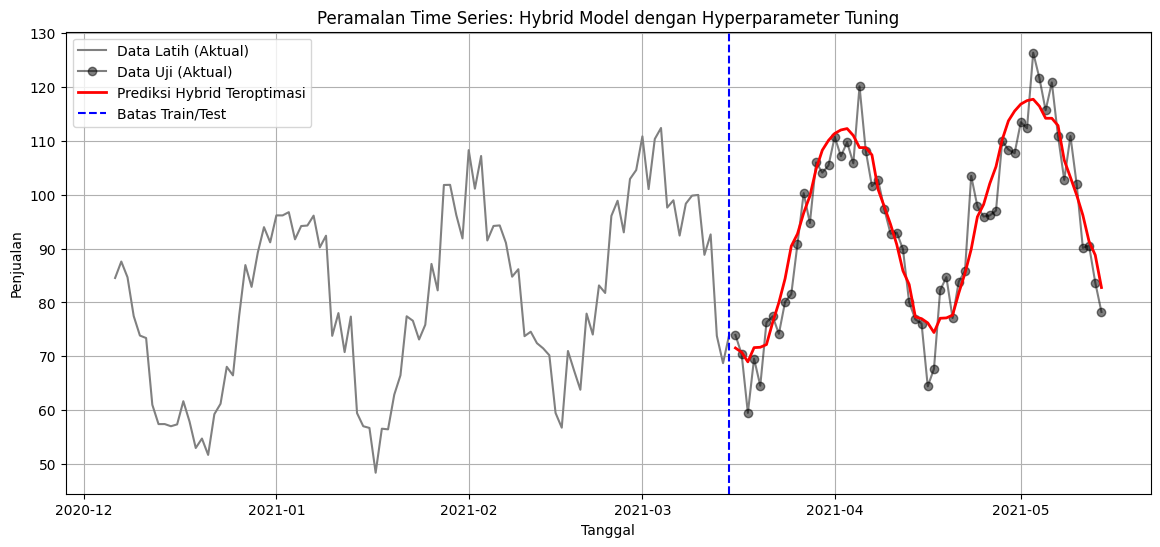

In [14]:
# Prediksi residual pada set pengujian menggunakan model XGBoost terbaik
pred_residual_test = pd.Series(best_xgb_model.predict(X_season_test), index=df_test.index)

# REKONSTRUKSI: Final Prediksi = Prediksi Tren + Prediksi Residual
pred_final_test = pred_trend_test + pred_residual_test

# Evaluasi Akhir
mae = mean_absolute_error(df_test['Sales'], pred_final_test)
print(f"Mean Absolute Error (Test Set): {mae:.2f}")

# Visualisasi
plt.figure(figsize=(14, 6))

# Plot Data Historis (Sebagian agar lebih jelas)
plt.plot(df_train.index[-100:], df_train['Sales'].iloc[-100:], label='Data Latih (Aktual)', color='gray')

# Plot Data Aktual Test Set
plt.plot(df_test.index, df_test['Sales'], label='Data Uji (Aktual)', marker='o', color='black', alpha=0.5)

# Plot Hasil Forecasting Final
plt.plot(df_test.index, pred_final_test, label='Prediksi Hybrid Teroptimasi', color='red', linewidth=2)

plt.title("Peramalan Time Series: Hybrid Model dengan Hyperparameter Tuning")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan")
plt.axvline(x=df_train.index[-1], color='blue', linestyle='--', label='Batas Train/Test')
plt.legend()
plt.grid(True)
plt.show()

ASSIGNMENT

Parameter XGBoost Terbaik: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Mean Absolute Error (Hold-out Test) TERBARU: 4.00


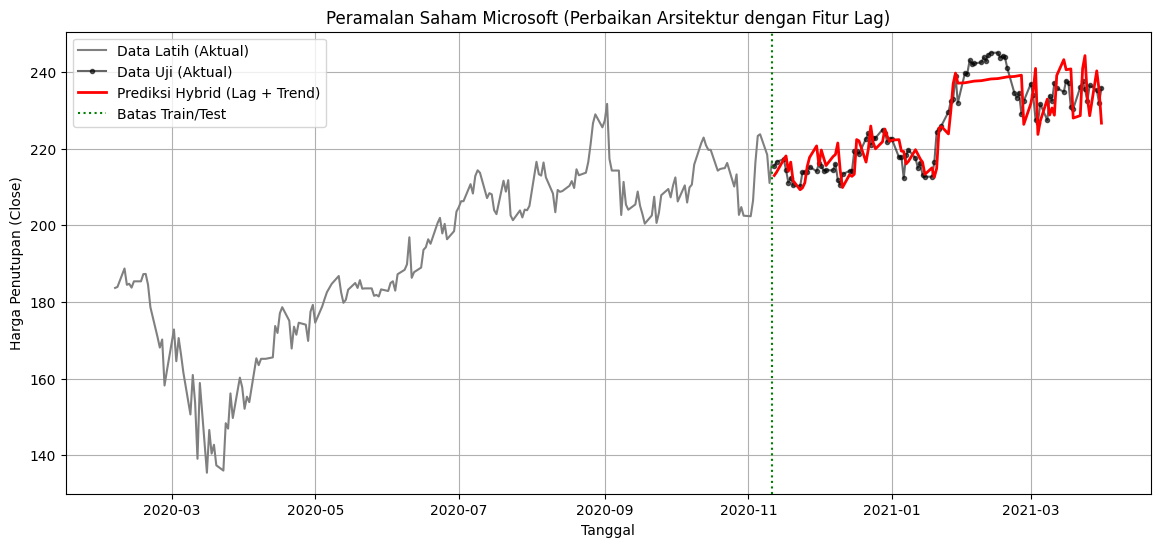

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.deterministic import DeterministicProcess

# ==========================================
# Bagian 1: Pra-pemrosesan Data
# ==========================================
df = pd.read_csv('Microsoft_Stock.csv')
df['Date'] = pd.to_datetime(df['Date']).dt.normalize()
df = df.set_index('Date').sort_index()
df = df.resample('B').ffill()

y = df['Close']
test_size = 100 

# ==========================================
# Bagian 2: Model 1 - Regresi Linier (Tren)
# ==========================================
# 1. Fitur Tren
dp = DeterministicProcess(index=y.index, order=1, constant=True)
X_trend = dp.in_sample()

# Split Data untuk Tren
y_train_full = y.iloc[:-test_size]
y_test = y.iloc[-test_size:]
X_trend_train = X_trend.iloc[:-test_size]
X_trend_test = X_trend.iloc[-test_size:]

# 2. Pelatihan Model Tren
model_trend = LinearRegression()
model_trend.fit(X_trend_train, y_train_full)

# 3. Prediksi Tren & Hitung Kesalahan (Residual)
pred_trend_train = pd.Series(model_trend.predict(X_trend_train), index=y_train_full.index)
pred_trend_test = pd.Series(model_trend.predict(X_trend_test), index=y_test.index)

# Menyatukan kembali target untuk keperluan pembuatan Lag (Shift)
residual_full = y - pd.concat([pred_trend_train, pred_trend_test])

# ==========================================
# Bagian 3: PERBAIKAN - Ekstraksi Fitur Lag
# ==========================================
# Mengganti fitur "Bulan/Kuartal" dengan Harga Masa Lalu (Lag 1, 2, 3)
X_lag = pd.DataFrame({
    'Lag_1': residual_full.shift(1),
    'Lag_2': residual_full.shift(2),
    'Lag_3': residual_full.shift(3)
})

# PENTING: Pergeseran (Shift) menghasilkan nilai kosong (NaN) di 3 baris pertama.
# Baris ini harus dibuang agar algoritma tidak error.
valid_idx = X_lag.dropna().index
X_lag = X_lag.loc[valid_idx]
residual_full = residual_full.loc[valid_idx]

# Menyelaraskan ulang indeks Train dan Test agar bebas dari NaN
train_idx = y_train_full.index.intersection(valid_idx)
test_idx = y_test.index

X_lag_train = X_lag.loc[train_idx]
X_lag_test = X_lag.loc[test_idx]
resid_train = residual_full.loc[train_idx]

# ==========================================
# Bagian 4: Model 2 - XGBoost (Tuning)
# ==========================================
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5]
}

tscv = TimeSeriesSplit(n_splits=4)
grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# XGBoost kini belajar dari relasi harga hari ini dengan hari sebelumnya
grid_search.fit(X_lag_train, resid_train)
best_xgb = grid_search.best_estimator_

print("Parameter XGBoost Terbaik:", grid_search.best_params_)

# ==========================================
# Bagian 5: Prediksi Final & Evaluasi
# ==========================================
pred_resid_test = pd.Series(best_xgb.predict(X_lag_test), index=X_lag_test.index)

# Rekonstruksi: Tren + Siklus/Lag
final_predictions = pred_trend_test + pred_resid_test

# Evaluasi
mae = mean_absolute_error(y_test, final_predictions)
print(f"Mean Absolute Error (Hold-out Test) TERBARU: {mae:.2f}")

# Visualisasi
plt.figure(figsize=(14, 6))

plt.plot(y_train_full.index[-200:], y_train_full.iloc[-200:], label='Data Latih (Aktual)', color='gray')
plt.plot(y_test.index, y_test, label='Data Uji (Aktual)', color='black', marker='.', alpha=0.6)
plt.plot(final_predictions.index, final_predictions, label='Prediksi Hybrid (Lag + Trend)', color='red', linewidth=2)

plt.title("Peramalan Saham Microsoft (Perbaikan Arsitektur dengan Fitur Lag)")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Close)")
plt.axvline(x=y_train_full.index[-1], color='green', linestyle=':', label='Batas Train/Test')
plt.legend()
plt.grid(True)
plt.show()

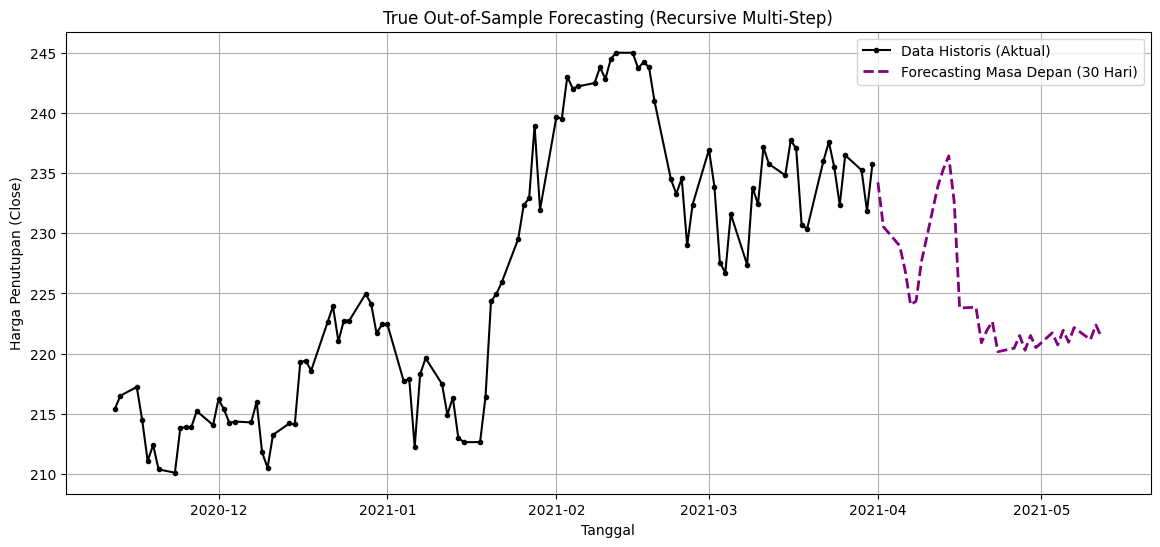

In [17]:
# ==========================================
# Bagian 6: TRUE OUT-OF-SAMPLE FORECASTING (RECURSIVE)
# Memprediksi 30 Hari Kerja ke depan (Masa Depan Murni)
# ==========================================
future_steps = 30

# 1. Buat Indeks Waktu Masa Depan (30 Hari Kerja ke depan)
last_date = y.index[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=future_steps, freq='B')

# 2. Ekstrapolasi Tren untuk 30 Hari Kedepan menggunakan Regresi Linier
# DeterministicProcess secara otomatis dapat menghasilkan fitur waktu ke masa depan
X_trend_future = dp.out_of_sample(steps=future_steps)
pred_trend_future = pd.Series(model_trend.predict(X_trend_future), index=future_dates)

# 3. Siapkan Array untuk menyimpan prediksi residual
# Ambil 3 nilai residual TERAKHIR dari data historis sebagai titik awal (Lag 3, Lag 2, Lag 1)
# Urutan: [Lag_3, Lag_2, Lag_1]
last_known_residuals = residual_full.iloc[-3:].tolist()
future_residuals = []

# 4. Looping Rekursif (Memasukkan prediksi hari ini sebagai Lag untuk besok)
for i in range(future_steps):
    # Siapkan DataFrame 1 baris yang berisi Lag saat ini
    current_lags = pd.DataFrame({
        'Lag_1': [last_known_residuals[-1]],
        'Lag_2': [last_known_residuals[-2]],
        'Lag_3': [last_known_residuals[-3]]
    })
    
    # Prediksi residual untuk hari ini menggunakan XGBoost
    pred_res = best_xgb.predict(current_lags)[0]
    future_residuals.append(pred_res)
    
    # UPDATE LAGS: Masukkan prediksi terbaru ke akhir list, buang yang paling lama
    # Sehingga array bergeser maju 1 hari
    last_known_residuals.append(pred_res)
    last_known_residuals.pop(0)

# Konversi list residual masa depan menjadi Pandas Series
pred_residual_future = pd.Series(future_residuals, index=future_dates)

# 5. Rekonstruksi Prediksi Masa Depan = Tren Masa Depan + Residual Masa Depan
true_out_of_sample_forecast = pred_trend_future + pred_residual_future

# ==========================================
# Visualisasi Forecasting Masa Depan
# ==========================================
plt.figure(figsize=(14, 6))

# Plot 100 hari terakhir dari data aktual sebagai konteks
plt.plot(y.index[-100:], y.iloc[-100:], label='Data Historis (Aktual)', color='black', marker='.')

# Plot hasil forecasting murni ke masa depan
plt.plot(true_out_of_sample_forecast.index, true_out_of_sample_forecast, 
         label='Forecasting Masa Depan (30 Hari)', color='purple', linestyle='--', linewidth=2)

plt.title("True Out-of-Sample Forecasting (Recursive Multi-Step)")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Close)")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
# ==========================================
# Bagian 6: CONTOH 1-STEP AHEAD FORECAST (Prediksi Besok)
# Memprediksi harga saham untuk 1 hari kerja ke depan secara murni
# ==========================================

# 1. Menentukan tanggal untuk "besok" (1 Hari Kerja setelah data terakhir)
last_date = y.index[-1]
next_date = last_date + pd.offsets.BDay(1)

# 2. Ekstrapolasi Tren untuk 1 hari ke depan menggunakan Regresi Linier
X_trend_tomorrow = dp.out_of_sample(steps=1)
pred_trend_tomorrow = model_trend.predict(X_trend_tomorrow)[0]

# 3. Menyiapkan Fitur Lag dari 3 hari terakhir data aktual
# Untuk memprediksi besok, model membutuhkan residual dari hari ini (Lag_1), 
# kemarin (Lag_2), dan lusa (Lag_3).
last_3_residuals = residual_full.iloc[-3:].values

X_lag_tomorrow = pd.DataFrame({
    'Lag_1': [last_3_residuals[2]], # Residual hari terakhir (paling baru)
    'Lag_2': [last_3_residuals[1]], # Residual 1 hari sebelumnya
    'Lag_3': [last_3_residuals[0]]  # Residual 2 hari sebelumnya
})

# 4. Memprediksi Residual untuk besok menggunakan XGBoost
pred_resid_tomorrow = best_xgb.predict(X_lag_tomorrow)[0]

# 5. Rekonstruksi Prediksi Akhir (Tren + Residual)
final_prediction_tomorrow = pred_trend_tomorrow + pred_resid_tomorrow

# 6. Menampilkan Hasil
print("\n" + "="*45)
print("HASIL 1-STEP AHEAD FORECAST (PREDIKSI BESOK)")
print("="*45)
print(f"Tanggal Terakhir Data   : {last_date.strftime('%Y-%m-%d')}")
print(f"Harga Aktual Terakhir   : ${y.iloc[-1]:.2f}\n")

print(f"Tanggal Prediksi        : {next_date.strftime('%Y-%m-%d')}")
print(f" -> Prediksi Tren Dasar : ${pred_trend_tomorrow:.2f}")
print(f" -> Prediksi Fluktuasi  : ${pred_resid_tomorrow:.2f}")
print(f" -> HARGA FINAL DITEBAK : ${final_prediction_tomorrow:.2f}")
print("="*45)


HASIL 1-STEP AHEAD FORECAST (PREDIKSI BESOK)
Tanggal Terakhir Data   : 2021-03-31
Harga Aktual Terakhir   : $235.77

Tanggal Prediksi        : 2021-04-01
 -> Prediksi Tren Dasar : $190.62
 -> Prediksi Fluktuasi  : $43.60
 -> HARGA FINAL DITEBAK : $234.23


BITCOIN

[*********************100%***********************]  1 of 1 completed


[*********************100%***********************]  1 of 1 completed

Mengunduh data BTC-USD dan SPY (S&P 500)...
Mengekstraksi Indikator & Fitur Makro...
Mempersiapkan Target T+5 dengan Stop-Loss 10%...

Melatih Model XGBClassifier...

HASIL EVALUASI SWING TRADING (T+5) DENGAN FILTER
Target Prediksi           : Tren 5 Hari (Lolos Stop-Loss 10%)
Akurasi Sinyal Eksekusi   : 63.22%
Coverage (Kesabaran Model): Eksekusi di 20.86% dari total waktu



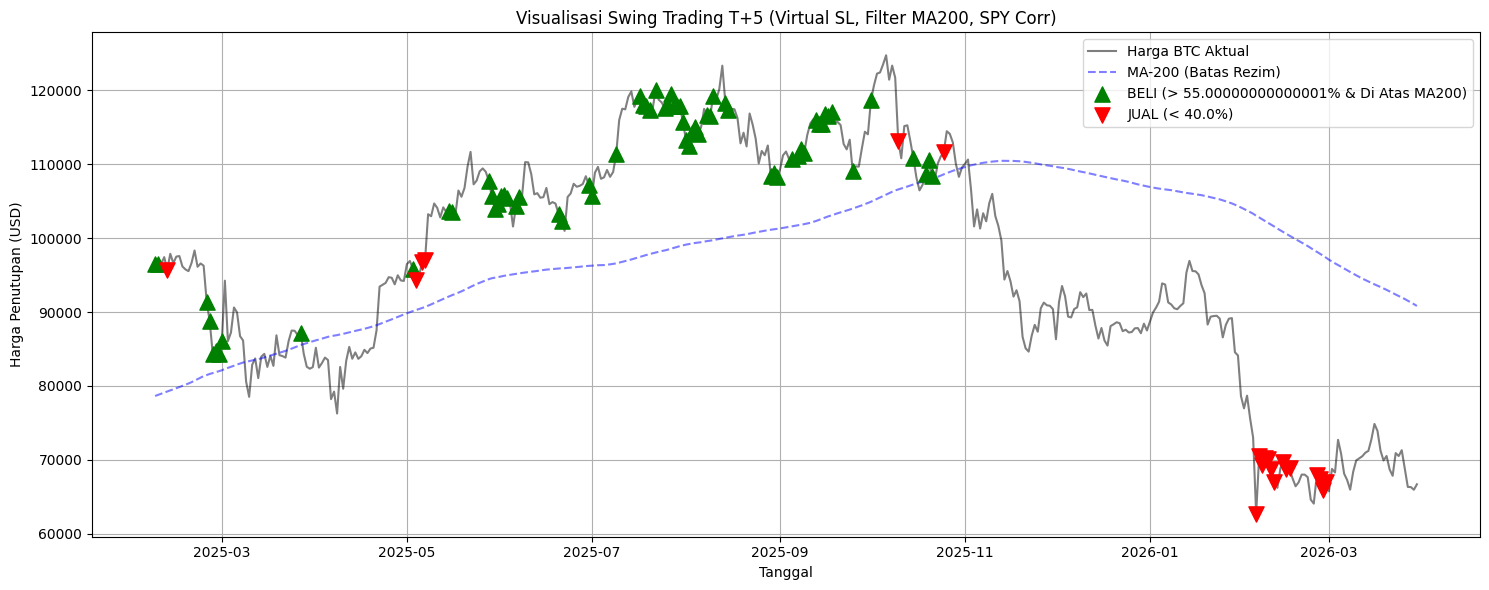

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# FUNGSI BANTUAN: Indikator Teknikal
# ==========================================
def calculate_rsi(series, period=14):
    delta = series.diff()
    gain = delta.where(delta > 0, 0).ewm(alpha=1/period, adjust=False).mean()
    loss = (-delta.where(delta < 0, 0)).ewm(alpha=1/period, adjust=False).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def calculate_macd(series, fast=12, slow=26, signal=9):
    ema_fast = series.ewm(span=fast, adjust=False).mean()
    ema_slow = series.ewm(span=slow, adjust=False).mean()
    macd = ema_fast - ema_slow
    macd_signal = macd.ewm(span=signal, adjust=False).mean()
    macd_hist = macd - macd_signal
    return macd, macd_signal, macd_hist

# ==========================================
# Bagian 1: Unduh Data (Termasuk 'Low' dan Data S&P 500)
# ==========================================
print("Mengunduh data BTC-USD dan SPY (S&P 500)...")
# Download BTC
df_btc = yf.download('BTC-USD', start='2020-01-01', end='2026-04-01')
df_btc.index = df_btc.index.tz_localize(None).normalize()
df_btc = df_btc.resample('D').ffill()

# Download SPY sebagai proxy sentimen makro (Intermarket feature)
df_spy = yf.download('SPY', start='2020-01-01', end='2026-04-01')
df_spy.index = df_spy.index.tz_localize(None).normalize()
df_spy = df_spy.resample('D').ffill()

data = pd.DataFrame(index=df_btc.index)
# Gunakan iloc[:, 0] untuk menghindari masalah multi-index pada pandas versi terbaru
data['Close'] = df_btc['Close'].iloc[:, 0] if isinstance(df_btc['Close'], pd.DataFrame) else df_btc['Close']
data['Low'] = df_btc['Low'].iloc[:, 0] if isinstance(df_btc['Low'], pd.DataFrame) else df_btc['Low']
data['Volume'] = df_btc['Volume'].iloc[:, 0] if isinstance(df_btc['Volume'], pd.DataFrame) else df_btc['Volume']

spy_close = df_spy['Close'].iloc[:, 0] if isinstance(df_spy['Close'], pd.DataFrame) else df_spy['Close']

data['Log_Ret'] = np.log(data['Close'] / data['Close'].shift(1))
data['SPY_Ret'] = np.log(spy_close / spy_close.shift(1))

# ==========================================
# Bagian 2: FEATURE ENGINEERING + EKSPLORASI FITUR
# ==========================================
print("Mengekstraksi Indikator & Fitur Makro...")

# 1. Momentum & Tren
data['RSI_14'] = calculate_rsi(data['Close'], 14)
data['MACD'], data['MACD_Signal'], data['MACD_Hist'] = calculate_macd(data['Close'])

# 2. Jarak dari Baseline Jangka Menengah
ma_50 = data['Close'].rolling(window=50).mean()
data['Dist_MA50'] = (data['Close'] - ma_50) / ma_50

# 3. Volatilitas Rezim
data['Vol_7'] = data['Log_Ret'].rolling(window=7).std()
data['Vol_30'] = data['Log_Ret'].rolling(window=30).std()
data['Vol_Ratio'] = data['Vol_7'] / data['Vol_30']

# 4. Korelasi Pasar (Fitur Alternatif Baru)
# Melihat apakah kripto sedang mengikuti saham (Risk-On) atau independen
data['Corr_SPY_30'] = data['Log_Ret'].rolling(window=30).corr(data['SPY_Ret'])

# 5. Filter Rezim Jangka Panjang (HANYA untuk Filter, bukan fitur model)
data['MA_200'] = data['Close'].rolling(window=200).mean()

# ==========================================
# Bagian 3: TARGET SWING + VIRTUAL STOP-LOSS
# ==========================================
print("Mempersiapkan Target T+5 dengan Stop-Loss 10%...")
future_steps = 5
STOP_LOSS_PCT = 0.10 # Stop loss 10%

# Cari harga terendah dalam 5 hari KE DEPAN
# shift(-future_steps) mundur 5 hari, rolling min akan mencari nilai terkecil di jendela itu
data['Min_Next_5D'] = data['Low'].shift(-1).iloc[::-1].rolling(window=future_steps, min_periods=1).min().iloc[::-1]

# Cek apakah dalam 5 hari tersebut harga menyentuh Stop Loss
data['Hit_SL'] = ((data['Close'] - data['Min_Next_5D']) / data['Close']) >= STOP_LOSS_PCT

# Kondisi Target: 
# 1 = Harga T+5 naik AND tidak pernah menyentuh Stop Loss selama perjalanan
# 0 = Harga T+5 turun OR menyentuh Stop Loss
is_higher_T5 = data['Close'].shift(-future_steps) > data['Close']
data['Target_T5_SL'] = (is_higher_T5 & (~data['Hit_SL'])).astype(int)

# Hapus missing values akibat rolling dan shift
data = data.dropna()

fitur_kolom = ['RSI_14', 'MACD', 'MACD_Hist', 'Dist_MA50', 'Vol_Ratio', 'Vol_7', 'Corr_SPY_30']
X = data[fitur_kolom]
y = data['Target_T5_SL']

# ==========================================
# Bagian 4: Pembagian Data & Pelatihan
# ==========================================
split_idx = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
dates_test = data.index[split_idx:]

print("\nMelatih Model XGBClassifier...")
model_clf = XGBClassifier(
    n_estimators=150, 
    learning_rate=0.01, 
    max_depth=4, 
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
model_clf.fit(X_train, y_train)

# ==========================================
# Bagian 5: KALIBRASI ASIMETRIS & FILTER REZIM MA-200
# ==========================================
probs_up = model_clf.predict_proba(X_test)[:, 1]

BUY_THRESHOLD = 0.55   
SELL_THRESHOLD = 0.40  

signals = []
# Ekstraksi MA200 untuk data test
test_ma200 = data['MA_200'].iloc[split_idx:].values
test_close = data['Close'].iloc[split_idx:].values

for i, p in enumerate(probs_up):
    is_bull_regime = test_close[i] > test_ma200[i]
    
    if p >= BUY_THRESHOLD:
        # FILTER REZIM: Jangan beli jika kita berada di bawah MA200 (Bear Market)
        if is_bull_regime:
            signals.append(1)
        else:
            signals.append(0) # Blokir sinyal beli menjadi netral
            
    elif p <= SELL_THRESHOLD:
        signals.append(-1)
    else:
        signals.append(0)

signals = np.array(signals)
actual_directions = np.where(y_test == 1, 1, -1)

# ==========================================
# Bagian 6: Evaluasi
# ==========================================
traded_indices = np.where(signals != 0)[0]
if len(traded_indices) > 0:
    acc_filtered = accuracy_score(actual_directions[traded_indices], signals[traded_indices]) * 100
    trade_coverage = (len(traded_indices) / len(y_test)) * 100
else:
    acc_filtered = 0
    trade_coverage = 0

print("\n" + "="*50)
print("HASIL EVALUASI SWING TRADING (T+5) DENGAN FILTER")
print("="*50)
print(f"Target Prediksi           : Tren 5 Hari (Lolos Stop-Loss 10%)")
print(f"Akurasi Sinyal Eksekusi   : {acc_filtered:.2f}%")
print(f"Coverage (Kesabaran Model): Eksekusi di {trade_coverage:.2f}% dari total waktu")
print("="*50 + "\n")

# ==========================================
# Bagian 7: Visualisasi Sinyal Swing
# ==========================================
plt.figure(figsize=(15, 6))

plt.plot(dates_test, test_close, label='Harga BTC Aktual', color='black', alpha=0.5, linewidth=1.5)
plt.plot(dates_test, test_ma200, label='MA-200 (Batas Rezim)', color='blue', linestyle='--', alpha=0.5)

# Titik Beli
buy_dates = dates_test[signals == 1]
buy_prices = test_close[signals == 1]
plt.scatter(buy_dates, buy_prices, marker='^', color='green', s=120, label=f'BELI (> {BUY_THRESHOLD*100}% & Di Atas MA200)', zorder=5)

# Titik Jual
sell_dates = dates_test[signals == -1]
sell_prices = test_close[signals == -1]
plt.scatter(sell_dates, sell_prices, marker='v', color='red', s=120, label=f'JUAL (< {SELL_THRESHOLD*100}%)', zorder=5)

plt.title("Visualisasi Swing Trading T+5 (Virtual SL, Filter MA200, SPY Corr)")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Menjalankan Simulasi Backtesting (Termasuk Fee 0.3%)...

LAPORAN KINERJA BACKTEST (SIMULASI $10,000 + FEE 0.3%)
Total Trade Dieksekusi : 33 kali
Win Rate (Net Profit)  : 57.58%
Total Fee Dibayar      : $1,977.22 ke Exchange
--------------------------------------------------
Modal Akhir (Bersih)   : $9,806.74
NET PROFIT (ROI)       : -1.93%
Max Drawdown (Risiko)  : -11.88%
--------------------------------------------------
Perbandingan Buy & Hold: -30.91%



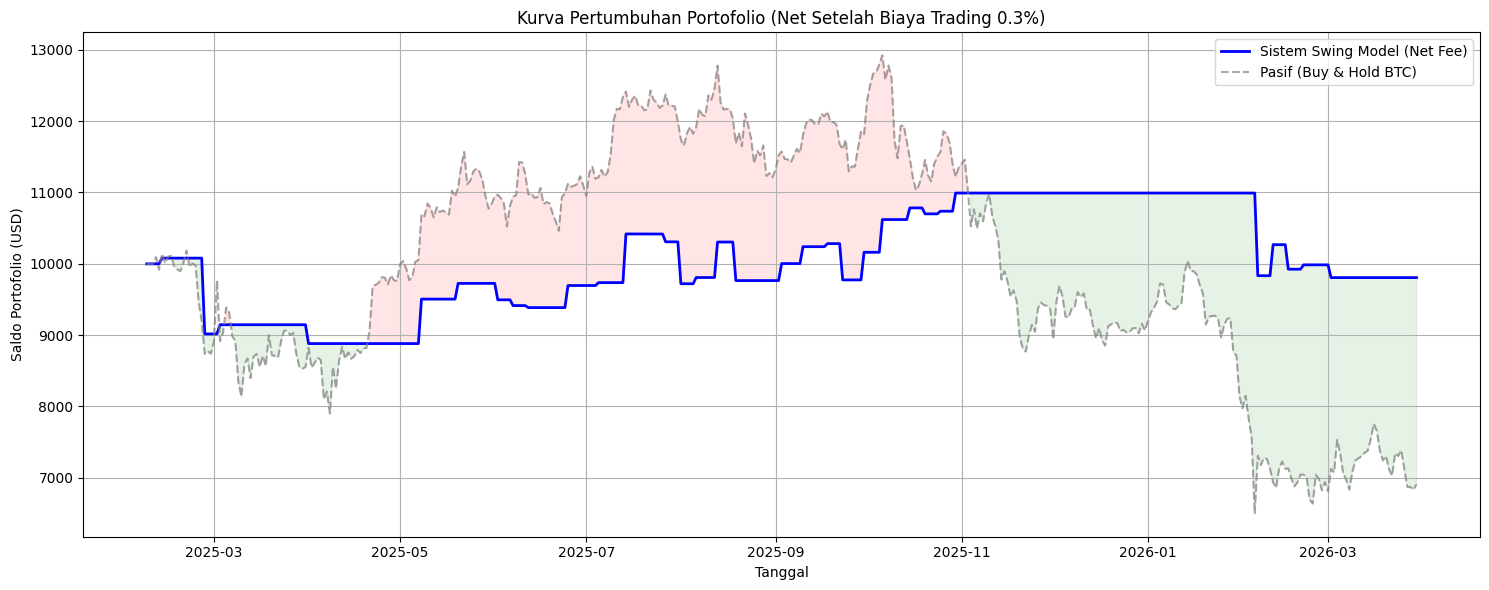

In [24]:
# ==========================================
# Bagian 8: SIMULASI BACKTESTING (DENGAN BIAYA TRADING)
# ==========================================
print("Menjalankan Simulasi Backtesting (Termasuk Fee 0.3%)...")

# --- Tambahkan kolom 'High' jika belum ada untuk cek Stop-Loss Short ---
if 'High' not in data.columns:
    data['High'] = df_btc['High'].iloc[:, 0] if isinstance(df_btc['High'], pd.DataFrame) else df_btc['High']

test_high = data['High'].iloc[split_idx:].values
test_low = data['Low'].iloc[split_idx:].values
# ----------------------------------------------------------------------

MODAL_AWAL = 10000.0
modal_sekarang = MODAL_AWAL
equity_curve = [MODAL_AWAL]
trade_log = []

# Parameter Biaya
FEE_PCT = 0.003  # 0.3% per transaksi (Beli kena 0.3%, Jual kena 0.3%)

# Status Trading
in_trade = False
trade_direction = 0     # 1 untuk Long, -1 untuk Short
entry_price = 0.0
entry_date = None
days_held = 0

# Iterasi hari demi hari di data Test
for i in range(len(dates_test)):
    current_date = dates_test[i]
    current_close = test_close[i]
    current_low = test_low[i]
    current_high = test_high[i]
    current_signal = signals[i]
    
    # 1. CEK KONDISI EXIT (Jika sedang dalam posisi)
    if in_trade:
        days_held += 1
        exit_triggered = False
        exit_price = 0.0
        exit_reason = ""
        
        # Cek Stop Loss (10%) selama masa penahanan
        if trade_direction == 1: # Posisi Beli (Long)
            if current_low <= entry_price * (1 - STOP_LOSS_PCT):
                exit_price = entry_price * (1 - STOP_LOSS_PCT)
                exit_reason = "Stop Loss (-10%)"
                exit_triggered = True
        elif trade_direction == -1: # Posisi Jual (Short)
            if current_high >= entry_price * (1 + STOP_LOSS_PCT):
                exit_price = entry_price * (1 + STOP_LOSS_PCT)
                exit_reason = "Stop Loss (-10%)"
                exit_triggered = True
                
        # Cek Take Profit Berbasis Waktu (Hari ke-5)
        if not exit_triggered and days_held == 5:
            exit_price = current_close
            exit_reason = "Time Exit (T+5)"
            exit_triggered = True
            
        # Eksekusi Exit
        if exit_triggered:
            # Hitung Return Trade (Kotor)
            if trade_direction == 1:
                gross_return = (exit_price - entry_price) / entry_price
            else:
                gross_return = (entry_price - exit_price) / entry_price
                
            # --- PERHITUNGAN BIAYA TRADING (FEE) ---
            modal_awal_trade = modal_sekarang
            
            # Potong fee saat masuk (Entry)
            biaya_entry = modal_awal_trade * FEE_PCT
            modal_bersih_entry = modal_awal_trade - biaya_entry
            
            # Kembangkan modal bersih dengan persentase kemenangan/kekalahan
            nilai_kotor_exit = modal_bersih_entry * (1 + gross_return)
            
            # Potong fee saat keluar (Exit)
            biaya_exit = nilai_kotor_exit * FEE_PCT
            modal_sekarang = nilai_kotor_exit - biaya_exit
            
            # Hitung net return dan total uang yang hilang untuk fee
            net_trade_return = (modal_sekarang - modal_awal_trade) / modal_awal_trade
            total_biaya_trade = biaya_entry + biaya_exit
            
            trade_log.append({
                'Entry Date': entry_date,
                'Exit Date': current_date,
                'Type': 'LONG' if trade_direction == 1 else 'SHORT',
                'Entry Price': entry_price,
                'Exit Price': exit_price,
                'Gross Return %': gross_return * 100,
                'Net Return %': net_trade_return * 100,
                'Fee Paid ($)': total_biaya_trade,
                'Reason': exit_reason,
                'Balance': modal_sekarang
            })
            
            # Reset Status
            in_trade = False
            trade_direction = 0
            days_held = 0
            
    # 2. CEK KONDISI ENTRY (Jika TIDAK sedang dalam posisi)
    if not in_trade:
        if current_signal == 1:
            in_trade = True
            trade_direction = 1
            entry_price = current_close
            entry_date = current_date
            days_held = 0
        elif current_signal == -1:
            in_trade = True
            trade_direction = -1
            entry_price = current_close
            entry_date = current_date
            days_held = 0
            
    equity_curve.append(modal_sekarang)

equity_curve = equity_curve[1:]

# ==========================================
# Bagian 9: METRIK KINERJA & VISUALISASI EQUITY
# ==========================================
df_trades = pd.DataFrame(trade_log)

if len(df_trades) > 0:
    total_trades = len(df_trades)
    winning_trades = len(df_trades[df_trades['Net Return %'] > 0]) # Win rate dihitung dari NET, bukan Gross
    win_rate = (winning_trades / total_trades) * 100
    
    # Hitung Total Biaya (Fee)
    total_fee_dibayar = df_trades['Fee Paid ($)'].sum()
    
    # Hitung Max Drawdown
    equity_series = pd.Series(equity_curve)
    rolling_max = equity_series.cummax()
    drawdown = (equity_series - rolling_max) / rolling_max
    max_drawdown = drawdown.min() * 100
    
    total_return_pct = ((modal_sekarang - MODAL_AWAL) / MODAL_AWAL) * 100
    buy_hold_return = ((test_close[-1] - test_close[0]) / test_close[0]) * 100

    print("\n" + "="*50)
    print("LAPORAN KINERJA BACKTEST (SIMULASI $10,000 + FEE 0.3%)")
    print("="*50)
    print(f"Total Trade Dieksekusi : {total_trades} kali")
    print(f"Win Rate (Net Profit)  : {win_rate:.2f}%")
    print(f"Total Fee Dibayar      : ${total_fee_dibayar:,.2f} ke Exchange")
    print("-" * 50)
    print(f"Modal Akhir (Bersih)   : ${modal_sekarang:,.2f}")
    print(f"NET PROFIT (ROI)       : {total_return_pct:.2f}%")
    print(f"Max Drawdown (Risiko)  : {max_drawdown:.2f}%")
    print("-" * 50)
    print(f"Perbandingan Buy & Hold: {buy_hold_return:.2f}%")
    print("="*50 + "\n")

    # Visualisasi
    plt.figure(figsize=(15, 6))
    plt.plot(dates_test, equity_curve, label='Sistem Swing Model (Net Fee)', color='blue', linewidth=2)
    
    buy_hold_curve = MODAL_AWAL * (test_close / test_close[0])
    plt.plot(dates_test, buy_hold_curve, label='Pasif (Buy & Hold BTC)', color='gray', linestyle='--', alpha=0.7)
    
    plt.title("Kurva Pertumbuhan Portofolio (Net Setelah Biaya Trading 0.3%)")
    plt.xlabel("Tanggal")
    plt.ylabel("Saldo Portofolio (USD)")
    plt.legend()
    plt.grid(True)
    plt.fill_between(dates_test, equity_curve, buy_hold_curve, where=(equity_curve > buy_hold_curve), color='green', alpha=0.1)
    plt.fill_between(dates_test, equity_curve, buy_hold_curve, where=(equity_curve <= buy_hold_curve), color='red', alpha=0.1)
    plt.tight_layout()
    plt.show()
else:
    print("Model tidak melakukan transaksi apapun pada periode pengujian.")